# 01 · Currency, USD amount and business vs consumer behaviour
**Owner:** Chan Jia Yi · **Needs:** run `04_integration_validation.ipynb` first (it builds `data/processed/`).

Three feature groups, one dashboard each. Rule IDs match `outputs/tables/rules_log.csv`, the charts and the slides. Every chart title states the rule.
The test statistics and verdicts for each rule are in notebook 04 (section 3).

| Group | Rules |
|---|---|
| Currency | R-CCY1 to R-CCY3 |
| USD amount | R-AMT1 to R-AMT3, plus rejected hypotheses N1 to N4 |
| Business vs consumer | R-BC1 to R-BC4 |

*Country* = bank (BIC) country. *Local currency* = the currency a country's senders use most, inferred from this data.

In [1]:
from pathlib import Path
import os, warnings; warnings.filterwarnings('ignore')
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, PROC = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed'
FIG, TAB = ROOT / 'outputs' / 'figures', ROOT / 'outputs' / 'tables'
RULES = TAB / 'rules'                       # one rules file per notebook -> combined into outputs/tables/rules_log.csv
for d in (RAW, PROC, FIG, TAB, RULES): d.mkdir(parents=True, exist_ok=True)
FULL    = PROC / 'payments_clean.parquet'   # all 10M rows (nothing removed) + derived columns, built by notebook 04
SAMPLE  = PROC / 'sample_20pct.parquet'     # 20% Bernoulli sample (seed 42), no free-text columns, still includes anomalies
ANOM    = PROC / 'anomalies.parquet'        # every labelled anomaly row, all columns
SCHEMA_VERSION = '2'                        # bump when derived columns change -> notebook 04 rebuilds the files

def connect(db=':memory:'):
    con = duckdb.connect(str(db))
    con.execute("SET TimeZone='UTC'")       # never skip: otherwise DuckDB shows laptop time (+08)
    con.execute("SET preserve_insertion_order=false")
    try: con.execute("SET enable_progress_bar=false")   # no progress widgets saved in the notebook ("Could not render ... widget" in viewers)
    except Exception: pass                           # (older setups without ipywidgets show no widget anyway)
    con.execute(f"SET temp_directory='{(PROC / 'duck_tmp').as_posix()}'")   # big joins spill to disk instead of crashing
    if os.environ.get('SWIFT_MEMORY'):  con.execute(f"SET memory_limit='{os.environ['SWIFT_MEMORY']}'")   # e.g. 4GB on an 8 GB laptop
    if os.environ.get('SWIFT_THREADS'): con.execute(f"SET threads={int(os.environ['SWIFT_THREADS'])}")
    return con

In [2]:
con = connect()

In [3]:
def sql(q):
    """Run SQL on the full data and return a pandas DataFrame."""
    return con.execute(q).df()
q = sql
def save_table(df, name):
    """Save a result table to outputs/tables/<name>.csv and return it for display."""
    df.to_csv(TAB / f'{name}.csv', index=False); return df

RULE_COLS = ['id', 'group', 'rule', 'test', 'value', 'verdict', 'evidence_files', 'interpretation']
VERDICTS = 'Confirmed (holds in >=99% of rows / effect matches) · Strong (95-99%) · Partial (70-95% or only in a subgroup) · Rejected'
def verdict_from_share(x):
    return 'Confirmed' if x >= 0.99 else 'Strong' if x >= 0.95 else 'Partial' if x >= 0.70 else 'Rejected'

def combine_rules():
    """Merge every outputs/tables/rules/rules_*.csv into one outputs/tables/rules_log.csv (shared schema)."""
    frames = []
    for f in sorted(RULES.glob('rules_*.csv')):
        d = pd.read_csv(f)
        ren = {'observed_evidence_table_or_chart': 'evidence_files', 'interpretation_real_world': 'interpretation', 'confidence': 'verdict'}
        d = d.rename(columns={k: v for k, v in ren.items() if k in d.columns and v not in d.columns})
        if 'rule' not in d.columns and {'when_condition', 'then_effect'} <= set(d.columns):
            d['rule'] = d.when_condition.astype(str) + ' -> ' + d.then_effect.astype(str)
        if 'value' not in d.columns and 'size' in d.columns: d['value'] = d['size']
        d['source'] = f.name; frames.append(d)
    if not frames: return pd.DataFrame(columns=RULE_COLS)
    out = pd.concat(frames, ignore_index=True)
    out = out[[c for c in RULE_COLS + ['source'] if c in out.columns] + [c for c in out.columns if c not in RULE_COLS + ['source']]]
    out.to_csv(TAB / 'rules_log.csv', index=False); return out

In [4]:
# Main view `p` = full data with the shared derived columns (see notebook 04, section 1)
assert FULL.exists() and (PROC / '_schema_version.txt').exists() and (PROC / '_schema_version.txt').read_text().strip() == SCHEMA_VERSION, \
    'Shared data missing or outdated: run notebooks/04_integration_validation.ipynb first'
con.execute(f"CREATE OR REPLACE VIEW p AS SELECT * FROM read_parquet('{FULL.as_posix()}')")
# Local currency of each BIC country = the currency its senders use most (inferred from this dataset, no external lookup)
con.execute("""CREATE OR REPLACE TABLE local_ccy AS
  SELECT o_cc AS cc, arg_max(CURRENCY_CODE, n) AS local_ccy FROM
  (SELECT o_cc, CURRENCY_CODE, count(*) n FROM p GROUP BY ALL) GROUP BY o_cc""")
print(f"{con.execute('SELECT count(*) FROM p').fetchone()[0]:,} payments loaded")

10,000,000 payments loaded


In [5]:
# Chart style (colour-blind-safe palette; text never in series colour)
C = {'B2B': '#2a78d6', 'B2C': '#eb6834', 'C2B': '#1baf7a', 'C2C': '#eda100', 'B': '#2a78d6', 'C': '#eb6834'}
GREY, TP, TS, GR = '#c3c2b7', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': GR, 'axes.labelcolor': TS, 'xtick.color': TS, 'ytick.color': TS,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GR, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'axes.titlesize': 11, 'axes.titlecolor': TP, 'figure.facecolor': 'white', 'legend.frameon': False})
def save(fig, name, note=None):
    if note: fig.text(0.01, 0.005, note, fontsize=8, color=TS)
    fig.tight_layout(rect=(0, 0.04 if note else 0, 1, 1)); fig.savefig(FIG / name, dpi=160); plt.show()

In [6]:
import pytz
TZMAP = {cc: z[0] for cc, z in pytz.country_timezones.items()}   # first zone for multi-zone countries (limitation)
def add_local_time(df, cc_col='o_cc'):
    """Adds local hour (lh) and weekday (ld, 0=Mon) of the sender BIC country. -1 if the country has no known zone."""
    ts = pd.to_datetime(df['EPOCH_SECONDS'], unit='s', utc=True)
    lh = np.full(len(df), -1); ld = np.full(len(df), -1)
    for z, idx in df.groupby(df[cc_col].map(TZMAP)).indices.items():
        t = ts.iloc[idx].dt.tz_convert(z); lh[idx] = t.dt.hour.values; ld[idx] = t.dt.dayofweek.values
    return df.assign(lh=lh, ld=ld)

In [7]:
# Modelling sample: normal (non-anomaly) payments from the 20% sample
n = pd.read_parquet(SAMPLE, columns=['EPOCH_SECONDS','CURRENCY_CODE','USD_AMOUNT','o_cc','b_cc','ORDERING_TYPE','BENEFICIARY_TYPE',
        'pair','anomaly','ORDERING_BIC8','ORDERING_ACCOUNT','TRANSACTION_TYPE_CODE','CURRENCY_CONVERSION_COUNT','PARTICIPANT_COUNT'])
n = n[n.anomaly == 'NONE'].reset_index(drop=True)
n['la'] = np.log(n.USD_AMOUNT)                                   # ln(amount)
n['ob'] = (n.ORDERING_TYPE == 'B').astype(float)                 # sender is business
n['bb'] = (n.BENEFICIARY_TYPE == 'B').astype(float)              # receiver is business
loc = sql('SELECT * FROM local_ccy').set_index('cc').local_ccy
print(f'{len(n):,} normal payments in the modelling sample')

2,000,487 normal payments in the modelling sample


## 1. Currency
**Hypothesis:** the payment currency is decided by the **sender's** country, not the receiver's.

In [8]:
ccy = sql("SELECT CURRENCY_CODE, count(*) n, median(USD_AMOUNT) median_usd FROM p GROUP BY 1 ORDER BY 2 DESC")
ccy['share'] = ccy.n / ccy.n.sum(); ccy.to_csv(TAB / 'ccy_counts.csv', index=False)
print(len(ccy), 'currencies;', f"top 5 = {ccy.share.head(5).sum():.1%} of payments"); ccy.head(10)

155 currencies; top 5 = 69.5% of payments


,CURRENCY_CODE,n,median_usd,share
0,EUR,3198639,4603.620,0.319864
1,USD,1702991,6373.370,0.170299
2,GBP,873781,3586.120,0.087378
3,CHF,803898,6098.550,0.080390
4,SGD,367648,6404.805,0.036765
5,CNY,324963,1347.220,0.032496
6,HKD,197458,4892.975,0.019746
7,JPY,184251,2812.370,0.018425
8,AUD,166877,4623.230,0.016688
9,CAD,111146,4706.400,0.011115


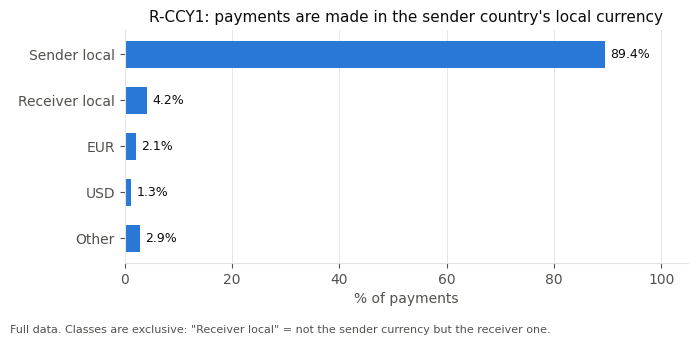

In [9]:
cls = sql("""SELECT CASE WHEN CURRENCY_CODE = ls.local_ccy THEN 'Sender local'
                         WHEN CURRENCY_CODE = lr.local_ccy THEN 'Receiver local'
                         WHEN CURRENCY_CODE IN ('EUR','USD') THEN CURRENCY_CODE ELSE 'Other' END AS cls, count(*) n
             FROM p LEFT JOIN local_ccy ls ON p.o_cc = ls.cc LEFT JOIN local_ccy lr ON p.b_cc = lr.cc GROUP BY 1""").set_index('cls').n
s = (cls / cls.sum() * 100).reindex(['Sender local', 'Receiver local', 'EUR', 'USD', 'Other']).fillna(0)
s.to_csv(TAB / 'ccy1_currency_choice.csv', header=['pct'])
fig, ax = plt.subplots(figsize=(7, 3.4)); bars = ax.barh(s.index[::-1], s.values[::-1], color=C['B'], height=0.6)
for r, v in zip(bars, s.values[::-1]): ax.text(v + 1, r.get_y() + r.get_height() / 2, f'{v:.1f}%', va='center', fontsize=9, color=TP)
ax.set_xlim(0, 105); ax.set_xlabel('% of payments'); ax.grid(axis='y', visible=False)
ax.set_title("R-CCY1: payments are made in the sender country's local currency")
save(fig, 'ccy1_currency_choice.png', 'Full data. Classes are exclusive: "Receiver local" = not the sender currency but the receiver one.')

**Hypothesis:** a conversion happens when money moves between two currency areas. A **Direct** payment (2 banks) should be converted exactly once if the two local currencies differ, and not at all otherwise.

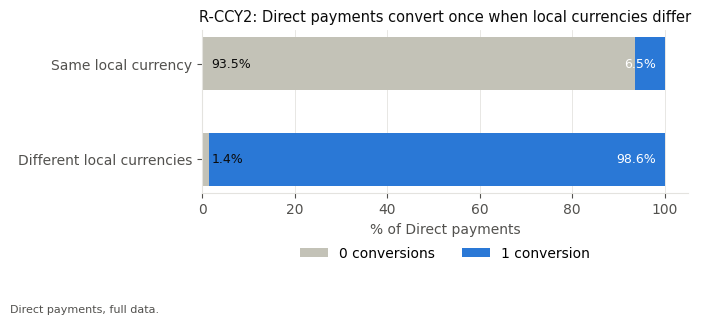

In [10]:
cv = sql("""SELECT CASE WHEN ls.local_ccy = lr.local_ccy THEN 'Same local currency' ELSE 'Different local currencies' END grp,
            CURRENCY_CONVERSION_COUNT k, count(*) n
            FROM p LEFT JOIN local_ccy ls ON p.o_cc = ls.cc LEFT JOIN local_ccy lr ON p.b_cc = lr.cc
            WHERE TRANSACTION_TYPE_CODE = 'Direct' GROUP BY ALL""").pivot(index='grp', columns='k', values='n').fillna(0)
t = cv.div(cv.sum(1), axis=0) * 100; t.to_csv(TAB / 'ccy2_direct_conversions.csv')
fig, ax = plt.subplots(figsize=(7, 3.2)); y = np.arange(len(t))
ax.barh(y, t[0], color=GREY, height=0.55, label='0 conversions'); ax.barh(y, t[1], left=t[0], color=C['B'], height=0.55, label='1 conversion')
for i, (a, b) in enumerate(zip(t[0], t[1])):
    ax.text(2, i, f'{a:.1f}%', va='center', fontsize=9, color=TP); ax.text(98, i, f'{b:.1f}%', va='center', ha='right', fontsize=9, color='white')
ax.set_yticks(y, t.index); ax.set_xlabel('% of Direct payments'); ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)
ax.set_title('R-CCY2: Direct payments convert once when local currencies differ', fontsize=10.5)
save(fig, 'ccy2_direct_conversion_rule.png', 'Direct payments, full data.')

In [11]:
# R-CCY3: conversions vs hops on multi-bank routes
hop = sql("""SELECT PARTICIPANT_COUNT - 1 AS hops, CURRENCY_CONVERSION_COUNT conv, count(*) n FROM p
             WHERE TRANSACTION_TYPE_CODE <> 'Direct' AND PARTICIPANT_COUNT <= 6 GROUP BY ALL""")
ht = hop.pivot(index='hops', columns='conv', values='n').fillna(0); ht = (ht.div(ht.sum(1), axis=0) * 100).round(1)
ht.to_csv(TAB / 'ccy3_conversions_by_hops.csv'); print('% of payments by number of conversions (columns) for each hop count (rows):'); ht

% of payments by number of conversions (columns) for each hop count (rows):


conv,0,1,2,3,4,5
hops,,,,,,
2,3.7,21.7,74.6,0.0,0.0,0.0
3,1.0,6.2,29.0,63.8,0.0,0.0
4,0.3,1.8,10.0,32.8,55.1,0.0
5,0.1,0.5,3.4,13.2,35.2,47.5


**Currency: findings**
- **R-CCY1:** 89.4% of payments use the sender country's currency. Only ~4% use the receiver's currency instead. The ~19% figure in notebook 04 also counts pairs where both countries share a currency, so the two numbers are not alternatives.
- **R-CCY2:** for Direct payments, "1 conversion if the local currencies differ, else 0" is right 97.8% of the time.
- **R-CCY3:** conversions never exceed the number of hops, so each bank on the route can convert at most once (see the hops table for the distribution).
- *Economic meaning:* the sender's bank debits in its home currency, and FX happens at the banks along the route (correspondent banking).
- *Limit:* the ~10% exceptions to R-CCY1 aren't explained yet.

## 2. USD amount
Step 1: screen which columns explain ln(amount) on their own. Step 2: model the strongest together and remove confounders.

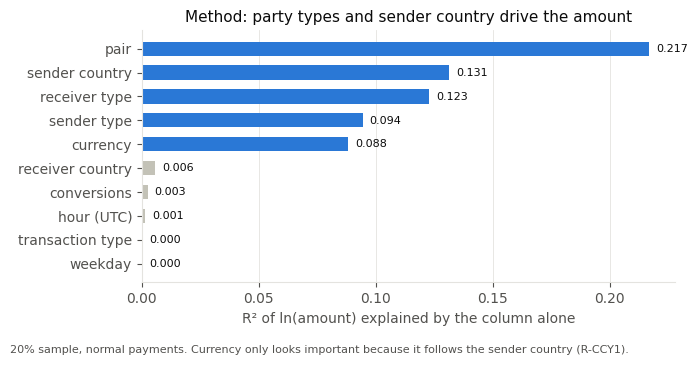

In [12]:
h = pd.to_datetime(n.EPOCH_SECONDS, unit='s')
fac = {'pair': n.pair, 'sender type': n.ORDERING_TYPE, 'receiver type': n.BENEFICIARY_TYPE, 'sender country': n.o_cc,
       'receiver country': n.b_cc, 'currency': n.CURRENCY_CODE, 'transaction type': n.TRANSACTION_TYPE_CODE,
       'conversions': n.CURRENCY_CONVERSION_COUNT, 'hour (UTC)': h.dt.hour, 'weekday': h.dt.dayofweek}
r2 = pd.Series({k: 1 - ((n.la - n.la.groupby(v).transform('mean')) ** 2).mean() / n.la.var() for k, v in fac.items()}).sort_values()
r2.to_csv(TAB / 'amt_factor_screening_r2.csv', header=['r2'])
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.barh(r2.index, r2.values, color=[C['B'] if v > 0.05 else GREY for v in r2.values], height=0.6)
for i, v in enumerate(r2.values): ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8, color=TP)
ax.set_xlabel('R² of ln(amount) explained by the column alone'); ax.grid(axis='y', visible=False)
ax.set_title('Method: party types and sender country drive the amount')
save(fig, 'amt0_factor_screening.png', '20% sample, normal payments. Currency only looks important because it follows the sender country (R-CCY1).')

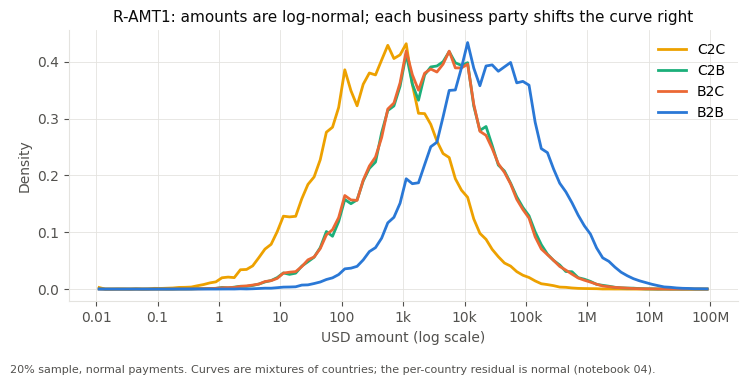

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8)); bins = np.arange(-2, 8.01, 0.1)
for pr in ['C2C', 'C2B', 'B2C', 'B2B']:
    hst, _ = np.histogram(np.log10(n.loc[n.pair == pr, 'USD_AMOUNT']), bins, density=True)
    ax.plot((bins[:-1] + bins[1:]) / 2, hst, color=C[pr], lw=2, label=pr)
ax.set_xticks(range(-2, 9), ['0.01','0.1','1','10','100','1k','10k','100k','1M','10M','100M'])
ax.set_xlabel('USD amount (log scale)'); ax.set_ylabel('Density'); ax.legend(loc='upper right')
ax.set_title('R-AMT1: amounts are log-normal; each business party shifts the curve right')
save(fig, 'amt1_lognormal_by_pair.png', '20% sample, normal payments. Curves are mixtures of countries; the per-country residual is normal (notebook 04).')

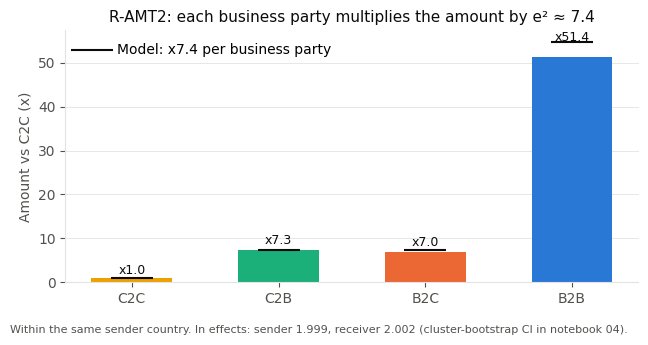

In [14]:
W = n[['la', 'ob', 'bb']] - n.groupby('o_cc')[['la', 'ob', 'bb']].transform('mean')   # remove sender-country effect
beta = np.linalg.lstsq(W[['ob', 'bb']].values, W.la.values, rcond=None)[0]
rel = (n.la - n.groupby('o_cc').la.transform('mean')).groupby(n.pair).mean().reindex(['C2C', 'C2B', 'B2C', 'B2B'])
rel = np.exp(rel - rel['C2C']); model = pd.Series(np.exp([0, beta[1], beta[0], beta.sum()]), index=rel.index)
pd.DataFrame({'observed_x_vs_C2C': rel, 'model_x': model}).to_csv(TAB / 'amt2_business_multiplier.csv')
fig, ax = plt.subplots(figsize=(6.5, 3.4)); ax.bar(rel.index, rel.values, color=[C[k] for k in rel.index], width=0.55)
ax.scatter(model.index, model.values, marker='_', s=900, color=TP, zorder=3, label=f'Model: x{np.exp(beta[0]):.1f} per business party')
for i, v in enumerate(rel.values): ax.text(i, v * 1.05 + 1, f'x{v:.1f}', ha='center', fontsize=9, color=TP)
ax.set_ylabel('Amount vs C2C (x)'); ax.legend(loc='upper left'); ax.grid(axis='x', visible=False)
ax.set_title('R-AMT2: each business party multiplies the amount by e² ≈ 7.4')
save(fig, 'amt2_business_multiplier.png', 'Within the same sender country. ln effects: sender %.3f, receiver %.3f (cluster-bootstrap CI in notebook 04).' % tuple(beta))

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


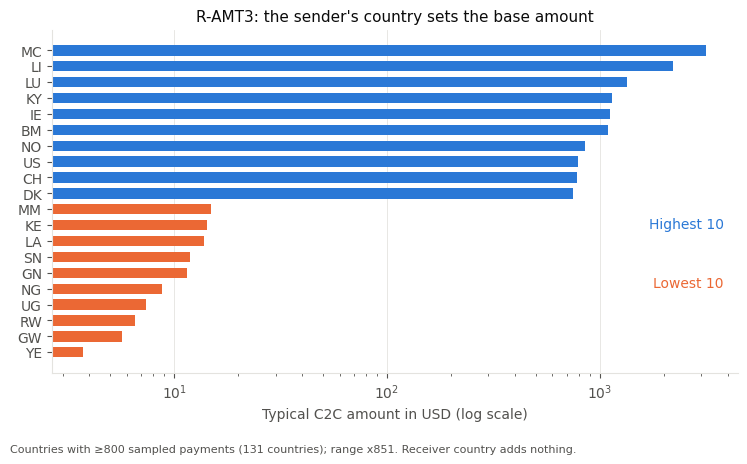

In [15]:
base = n.assign(b=n.la - beta[0] * n.ob - beta[1] * n.bb).groupby('o_cc').agg(N=('b', 'size'), ln_base=('b', 'mean'))
base['typical_C2C_usd'] = np.exp(base.ln_base); base = base[base.N >= 800].sort_values('ln_base')
base.to_csv(TAB / 'amt3_country_base_amount.csv')
sel = pd.concat([base.head(10), base.tail(10)])
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(range(20), sel.typical_C2C_usd, color=[C['C']] * 10 + [C['B']] * 10, height=0.65); ax.set_xscale('log')
ax.set_yticks(range(20), sel.index); ax.set_xlabel('Typical C2C amount in USD (log scale)'); ax.grid(axis='y', visible=False)
ax.text(0.98, 0.42, 'Highest 10', transform=ax.transAxes, ha='right', color=C['B']); ax.text(0.98, 0.25, 'Lowest 10', transform=ax.transAxes, ha='right', color=C['C'])
ax.set_title("R-AMT3: the sender's country sets the base amount")
save(fig, 'amt3_country_base_amount.png', f'Countries with ≥800 sampled payments ({len(base)} countries); range x{base.typical_C2C_usd.max()/base.typical_C2C_usd.min():.0f}. Receiver country adds nothing.')

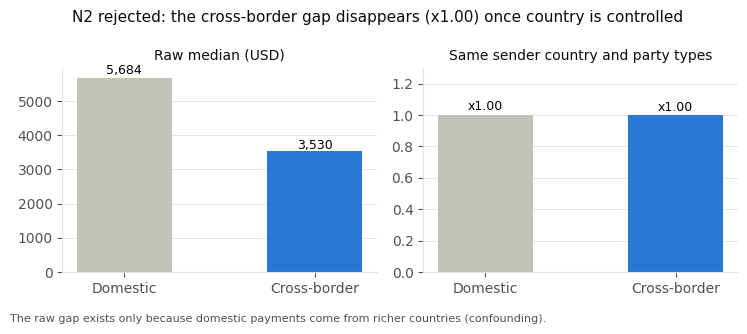

In [16]:
# Rejected hypothesis N2: the domestic vs cross-border gap is caused by country mix
n['xb'] = (n.o_cc != n.b_cc).astype(float)
Wx = n[['la', 'ob', 'bb', 'xb']] - n.groupby('o_cc')[['la', 'ob', 'bb', 'xb']].transform('mean')
bx = np.linalg.lstsq(Wx[['ob', 'bb', 'xb']].values, Wx.la.values, rcond=None)[0][2]
raw = n.groupby('xb').USD_AMOUNT.median()
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.2))
ax[0].bar(['Domestic', 'Cross-border'], raw.values, color=[GREY, C['B']], width=0.5); ax[0].set_title('Raw median (USD)', fontsize=10)
for i, v in enumerate(raw.values): ax[0].text(i, v * 1.02, f'{v:,.0f}', ha='center', fontsize=9)
ax[1].bar(['Domestic', 'Cross-border'], [1, np.exp(bx)], color=[GREY, C['B']], width=0.5); ax[1].set_ylim(0, 1.3)
for i, v in enumerate([1, np.exp(bx)]): ax[1].text(i, v + 0.03, f'x{v:.2f}', ha='center', fontsize=9)
ax[1].set_title('Same sender country and party types', fontsize=10)
for a in ax: a.grid(axis='x', visible=False)
fig.suptitle(f'N2 rejected: the cross-border gap disappears (x{np.exp(bx):.2f}) once country is controlled', fontsize=11, color=TP)
save(fig, 'amt4_crossborder_confounder.png', 'The raw gap exists only because domestic payments come from richer countries (confounding).')

**USD amount: findings**
- **R-AMT1:** within a sender country, ln(amount) is normal (skew ≈ 0, excess kurtosis ≈ 0, sd ≈ 2.08 for every pair), so amounts are **log-normal**.
- **R-AMT2:** a business sender and a business receiver each add **+2.0** to ln(amount), i.e. **x7.4 each** (95% cluster-bootstrap CI includes 2.0). B2B is about 55x C2C, and the two effects don't interact.
- **R-AMT3:** the **sender's** country sets the base level. The receiver's country adds almost nothing (R² ≈ 0.0003).
- **Model:** `ln(USD_AMOUNT) ~ Normal(base[sender country] + 2·[sender is B] + 2·[receiver is B], 2.08²)`
- **Rejected:** N1 (the handout's vowel/consonant rule), N2 (cross-border: a confounder), N3 (non-local currency), N4 (time or route type). See `rules_log.csv`.
- *Economic meaning:* businesses pay invoices and payroll, while consumers send personal transfers. The country base lines up with national income: financial centres (MC, LI, LU, KY) are highest and low-income economies lowest. On the slide, show this next to GDP per capita, cited in APA as an **external reference statistic**. The handbook (Sec. 3) allows this. It is not used as an input dataset.

## 3. Business vs consumer behaviour

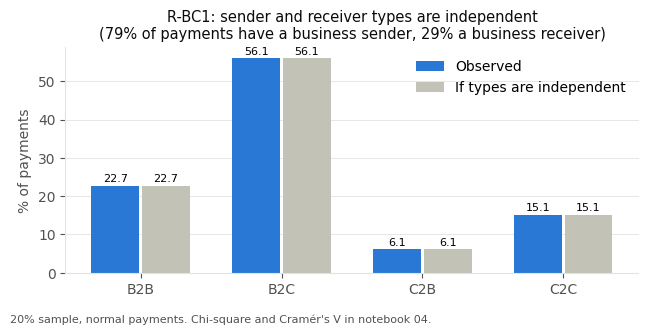

In [17]:
pob, pbb = n.ob.mean(), n.bb.mean(); obs = n.pair.value_counts(normalize=True) * 100
exp = pd.Series({'B2B': pob * pbb, 'B2C': pob * (1 - pbb), 'C2B': (1 - pob) * pbb, 'C2C': (1 - pob) * (1 - pbb)}) * 100
pd.DataFrame({'observed_%': obs.reindex(exp.index), 'independent_%': exp}).to_csv(TAB / 'bc1_pair_independence.csv')
fig, ax = plt.subplots(figsize=(6.5, 3.3)); x = np.arange(4)
ax.bar(x - 0.18, obs.reindex(exp.index), 0.34, color=C['B'], label='Observed'); ax.bar(x + 0.18, exp, 0.34, color=GREY, label='If types are independent')
for i, (o, e) in enumerate(zip(obs.reindex(exp.index), exp)):
    ax.text(i - 0.18, o + 1, f'{o:.1f}', ha='center', fontsize=8); ax.text(i + 0.18, e + 1, f'{e:.1f}', ha='center', fontsize=8)
ax.set_xticks(x, exp.index); ax.set_ylabel('% of payments'); ax.legend(); ax.grid(axis='x', visible=False)
ax.set_title(f'R-BC1: sender and receiver types are independent\n({pob:.0%} of payments have a business sender, {pbb:.0%} a business receiver)', fontsize=10.5)
save(fig, 'bc1_type_independence.png', "20% sample, normal payments. Chi-square and Cramér's V in notebook 04.")

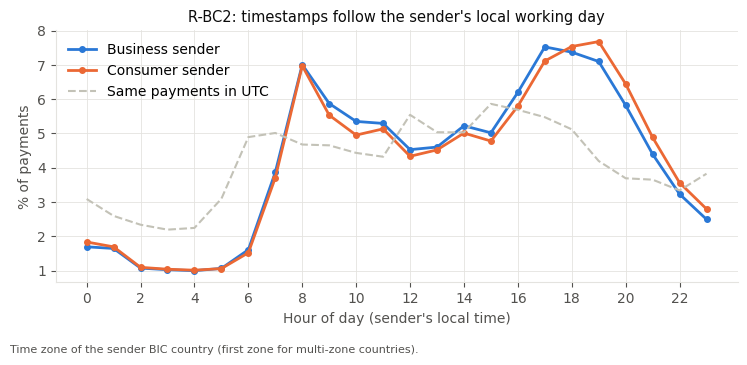

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
ORDERING_TYPE,,,,,,,
B,18.8,17.0,17.0,18.0,19.0,3.7,6.5
C,18.8,17.1,16.9,18.0,19.0,3.7,6.4


In [18]:
lt = add_local_time(n); lt = lt[lt.lh >= 0]
prof = pd.crosstab(lt.lh, lt.ORDERING_TYPE, normalize='columns') * 100
prof['UTC'] = pd.to_datetime(lt.EPOCH_SECONDS, unit='s').dt.hour.value_counts(normalize=True).sort_index() * 100
prof.to_csv(TAB / 'bc2_hour_profile.csv')
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for t, lab in [('B', 'Business sender'), ('C', 'Consumer sender')]: ax.plot(prof.index, prof[t], color=C[t], lw=2, marker='o', ms=4, label=lab)
ax.plot(prof.index, prof.UTC, color=GREY, lw=1.5, ls='--', label='Same payments in UTC')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day (sender's local time)"); ax.set_ylabel('% of payments'); ax.legend(loc='upper left')
ax.set_title("R-BC2: timestamps follow the sender's local working day", fontsize=10.5)
save(fig, 'bc2_local_hour_profile.png', 'Time zone of the sender BIC country (first zone for multi-zone countries).')
wd = (pd.crosstab(lt.ld, lt.ORDERING_TYPE, normalize='columns') * 100).round(1); wd.index = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
wd.to_csv(TAB / 'bc2_weekday_profile.csv'); wd.T

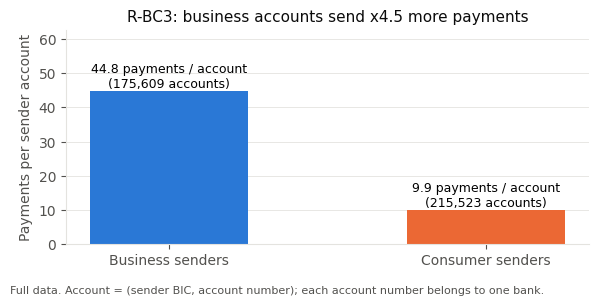

In [19]:
act = sql("""SELECT ORDERING_TYPE t, count(DISTINCT (ORDERING_BIC8, ORDERING_ACCOUNT)) accounts, count(*) payments FROM p GROUP BY 1 ORDER BY 1""")
act['per_account'] = act.payments / act.accounts; act.to_csv(TAB / 'bc3_activity_per_account.csv', index=False)
fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(['Business senders', 'Consumer senders'], act.per_account, color=[C['B'], C['C']], width=0.5)
for i, r in act.iterrows(): ax.text(i, r.per_account + 1, f'{r.per_account:.1f} payments / account\n({r.accounts:,} accounts)', ha='center', fontsize=9)
ax.set_ylim(0, act.per_account.max() * 1.4); ax.set_ylabel('Payments per sender account'); ax.grid(axis='x', visible=False)
ax.set_title(f'R-BC3: business accounts send x{act.per_account[0] / act.per_account[1]:.1f} more payments', fontsize=11)
save(fig, 'bc3_activity_per_account.png', 'Full data. Account = (sender BIC, account number); each account number belongs to one bank.')

In [20]:
ap = sql("SELECT anomaly, pair, count(*) n FROM p WHERE anomaly <> 'NONE' GROUP BY ALL").pivot(index='anomaly', columns='pair', values='n').fillna(0).astype(int)
ap.to_csv(TAB / 'bc4_anomaly_by_pair.csv'); ap

pair,B2B,B2C,C2B,C2C
anomaly,,,,
ACCOUNT_REPLACEMENT_SCAM,138,370,34,107
CEO_SCAM,262,683,0,0
CUSTOMER_RECALL,63,183,22,49
DUPLICATE_PAYMENT,152,393,21,113
FAT_FINGER_MISTAKE,445,1098,101,296
ROMANCE_SCAM,0,0,665,1811


**Business vs consumer: findings**
- **R-BC1:** sender type and receiver type are drawn independently. About 79% of payments have a business sender and 29% a business receiver (shares of payments, not of people), so B2C is the most common pair.
- **R-BC2:** timestamps follow the sender's **local** working day (08:00 peak, lunch dip, 17:00–19:00 peak, quiet nights and weekends). Businesses and consumers have the **same** timing (a rejected difference).
- **R-BC3:** a business sender account sends about 4.5x more payments than a consumer account over the data window.
- **R-BC4:** fraud follows party type. CEO scams only come from business senders and romance scams only from consumer senders.
- *Economic meaning:* companies pay many suppliers and staff, banks process payments in office hours, and each scam targets a specific kind of victim.
- *Note:* the detailed anomaly analysis (duplicates, fat finger, romance, account replacement) is in notebook 03.